# Loan Eligibility Prediction
## Data Analysis and Preprocessing Report

---

| Detail | Information |
|---|---|
| **Project Title** | Loan Eligibility Prediction using Machine Learning |
| **Domain** | Banking and Finance |
| **Task Type** | Binary Classification (Loan Approved / Rejected) |
| **Dataset** | Eligibility Prediction for Loan |
| **Dataset Source** | https://www.kaggle.com/datasets/devzohaib/eligibility-prediction-for-loan |
| **Dataset Author** | devzohaib (Kaggle) |
| **License** | CC0: Public Domain |
| **File Used** | Loan_Data.csv — 614 rows x 13 columns |
| **Language** | Python 3 |


---

## Team

| Name | Roll Number  |
|---|---|
| **Bhushan Avhad** | 25101B2006 |
| **Shreedhar Khorate** | 25101B2007 |

---

## Business Context

Dream Housing Finance company deals in all home loan types and has a presence across
Urban, Semi-Urban, and Rural areas. A customer first applies for a home loan, after which
the company validates the customer's eligibility. The goal of this project is to
**automate the loan eligibility process in real time** based on customer details
submitted through an online application form.

Details collected include: Gender, Marital Status, Education, Number of Dependents,
Income, Loan Amount, Credit History, and Property Area.

---

## Dataset Glossary

| Variable | Type | Unit | Description |
|---|---|---|---|
| Loan_ID | String | — | Unique loan reference number |
| Gender | Categorical | — | Male / Female |
| Married | Categorical | — | Applicant married? (Y / N) |
| Dependents | Ordinal | — | Number of dependents (0, 1, 2, 3+) |
| Education | Categorical | — | Graduate / Not Graduate |
| Self_Employed | Categorical | — | Self-employed? (Y / N) |
| ApplicantIncome | Numeric | INR/month | Monthly income of applicant |
| CoapplicantIncome | Numeric | INR/month | Monthly income of co-applicant |
| LoanAmount | Numeric | INR thousands | Loan amount requested |
| Loan_Amount_Term | Numeric | Months | Duration of the loan |
| Credit_History | Binary | — | Credit history meets guidelines (1=Yes, 0=No) |
| Property_Area | Categorical | — | Urban / Semiurban / Rural |
| Loan_Status | Target | — | Loan approved? (Y = Approved, N = Rejected) |

**Note:** LoanAmount is stored in thousands of INR. A value of 128 means INR 1,28,000.

---

## Notebook Contents

| Section | Description |
|---|---|
| 0 | Import libraries |
| 1 | Load and inspect the dataset |
| 2 | Missing value analysis |
| 3 | Invalid and inconsistent value detection |
| 4 | Distribution visualisations before cleaning |
| 5 | Missing value imputation |
| 6 | Outlier detection and removal using IQR |
| 7 | Feature engineering |
| 8 | Categorical encoding |
| 9 | Feature scaling |
| 10 | Correlation analysis |
| 11 | Final summary and export |

---
## Section 0 — Import Libraries

All required libraries are imported here at the top of the notebook.

- **pandas**: Data manipulation and analysis.
- **numpy**: Numerical operations and array handling.
- **matplotlib / seaborn**: Data visualisation.
- **scipy.stats**: Statistical computations.
- **sklearn**: Machine learning preprocessing utilities (LabelEncoder, StandardScaler).

Global plot settings and warnings are also configured here.

In [94]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [95]:
# -----------------------------------------------------------------------
# Section 0: Import Libraries
# Purpose : Load all necessary Python libraries before any other code.
# -----------------------------------------------------------------------

import pandas as pd          # Data loading, manipulation, and analysis
import numpy as np           # Numerical operations
import matplotlib.pyplot as plt  # Base plotting library
import seaborn as sns        # Statistical data visualisation
from scipy import stats      # Statistical functions
from sklearn.preprocessing import LabelEncoder, StandardScaler  # ML preprocessing

# Global plot appearance settings
plt.rcParams['figure.figsize'] = (12, 5)   # Default figure size
plt.rcParams['font.family']    = 'DejaVu Sans'  # Consistent font
sns.set_theme(style='whitegrid', palette='muted')  # Seaborn theme

import warnings
warnings.filterwarnings('ignore')  # Suppress non-critical warnings for cleaner output

print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## Section 1 — Load Dataset

**Source:** https://www.kaggle.com/datasets/devzohaib/eligibility-prediction-for-loan

The CSV file (`Loan_Data.csv`) is the training split of the Dream Housing Finance
loan dataset. It contains historical customer records where the loan outcome
(`Loan_Status`) is already known, making it suitable for supervised classification.

We begin by:
1. Reading the CSV into a pandas DataFrame.
2. Printing the shape (rows x columns).
3. Viewing the first 10 rows.
4. Inspecting data types and memory usage.
5. Reviewing descriptive statistics for both numeric and categorical columns.

In [96]:
# -----------------------------------------------------------------------
# Section 1a: Load the CSV file
# Purpose : Read Loan_Data.csv into a DataFrame and confirm it loaded.
# -----------------------------------------------------------------------

df = pd.read_csv('/content/drive/MyDrive/Loan/Loan_Data.csv')  # Load dataset from the working directory

print(f'Dataset loaded successfully.')
print(f'Shape : {df.shape[0]} rows x {df.shape[1]} columns')
df.head(10)  # Display the first 10 records for a quick visual check

Dataset loaded successfully.
Shape : 614 rows x 13 columns


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [97]:
# -----------------------------------------------------------------------
# Section 1b: Column information
# Purpose : Display column names, non-null counts, and data types.
#           This gives the first hint of missing values and type mismatches.
# -----------------------------------------------------------------------

print('Column Information:')
print('-' * 50)
df.info()

Column Information:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [98]:
# -----------------------------------------------------------------------
# Section 1c: Descriptive statistics for numeric columns
# Purpose : Summarise count, mean, std, min, quartiles, and max for each
#           numeric feature. Transposed (.T) for easier row-by-row reading.
# Note    : A count lower than total rows indicates missing values.
# -----------------------------------------------------------------------

print('Descriptive Statistics (Numeric Columns):')
print('-' * 50)
df.describe().T  # .T transposes: each feature becomes a row, stats become columns

Descriptive Statistics (Numeric Columns):
--------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


In [99]:
# -----------------------------------------------------------------------
# Section 1d: Descriptive statistics for categorical columns
# Purpose : Show unique value count, top category, and its frequency
#           for each object-type (categorical) column.
#           Helps spot unexpected categories or typos.
# -----------------------------------------------------------------------

print('Descriptive Statistics (Categorical Columns):')
print('-' * 50)
df.describe(include='object').T

Descriptive Statistics (Categorical Columns):
--------------------------------------------------


,count,unique,top,freq
Loan_ID,614,614,LP002990,1
Gender,601,2,Male,489
Married,611,2,Yes,398
Dependents,599,4,0,345
Education,614,2,Graduate,480
Self_Employed,582,2,No,500
Property_Area,614,3,Semiurban,233
Loan_Status,614,2,Y,422


---
## Section 2 — Missing Value Analysis

Missing values can bias model training or cause runtime errors if left unhandled.
This section identifies every column that contains null (NaN) values and quantifies
the extent of missingness, both as a raw count and as a percentage of total rows.

Two visualisations are produced:
1. **Bar chart** — percentage of missing values per column.
2. **Heatmap (nullity matrix)** — shows the pattern of missing values across rows,
   which helps detect whether missingness is random or systematic.

In [100]:
# -----------------------------------------------------------------------
# Section 2a: Count and percentage of missing values
# Purpose : Build a summary table of columns with at least one null.
#           Sorted in descending order of missing percentage.
# -----------------------------------------------------------------------

missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),                          # Absolute count
    'Missing %'    : (df.isnull().sum() / len(df) * 100).round(2)  # Percentage
})

# Keep only columns that have at least one missing value
missing = missing[missing['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print('Columns with missing values:')
print(missing.to_string())

Columns with missing values:
                  Missing Count  Missing %
Credit_History               50       8.14
Self_Employed                32       5.21
LoanAmount                   22       3.58
Dependents                   15       2.44
Loan_Amount_Term             14       2.28
Gender                       13       2.12
Married                       3       0.49


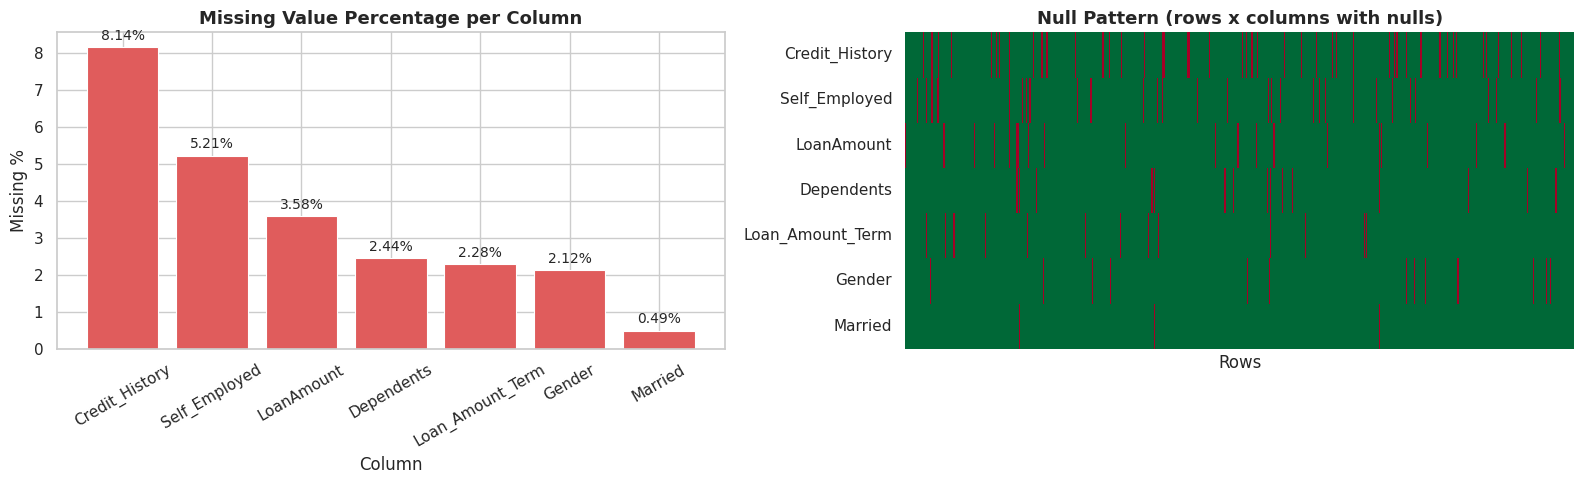

In [101]:
# -----------------------------------------------------------------------
# Section 2b: Visualise missing values
# Purpose : Two plots side by side:
#   Left  - Bar chart showing % missing per column.
#   Right - Heatmap (nullity matrix) showing where nulls appear row-by-row.
#           Red = missing, Green = present.
# -----------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Left: Bar chart ---
axes[0].bar(missing.index, missing['Missing %'],
            color='#e05c5c', edgecolor='white', linewidth=0.8)
axes[0].set_title('Missing Value Percentage per Column', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Missing %')
axes[0].set_xlabel('Column')
axes[0].tick_params(axis='x', rotation=30)
# Annotate each bar with the percentage value
for i, v in enumerate(missing['Missing %']):
    axes[0].text(i, v + 0.2, f'{v}%', ha='center', fontsize=10)

# --- Right: Nullity heatmap ---
# Convert True/False null mask to 0/1 integers for heatmap rendering
null_matrix = df[missing.index].isnull().astype(int)
sns.heatmap(null_matrix.T, ax=axes[1], cmap='RdYlGn_r', cbar=False,
            yticklabels=missing.index, xticklabels=False)
axes[1].set_title('Null Pattern (rows x columns with nulls)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Rows')

plt.tight_layout()
plt.show()

---
## Section 3 — Invalid and Inconsistent Value Detection

Beyond missing values, a dataset may contain:
- **Invalid values**: values that are logically impossible (e.g. negative income).
- **Inconsistent categories**: unexpected strings or extra whitespace in text fields.
- **Duplicate rows**: records that appear more than once.
- **Suspicious outliers**: values that are technically valid but statistically
  implausible (e.g. applicant income of INR 150/month).

This section checks all four of these issues and removes the suspicious
low-income records before imputation.

In [102]:
# -----------------------------------------------------------------------
# Section 3a: Unique values in categorical columns
# Purpose : Print every distinct value per categorical column to detect
#           unexpected categories, typos, or extra whitespace.
#           NaN entries indicate missing values in that column.
# -----------------------------------------------------------------------

cat_cols = ['Gender', 'Married', 'Dependents', 'Education',
            'Self_Employed', 'Property_Area', 'Loan_Status']

print('Unique values per categorical column (including NaN):')
print('-' * 55)
for col in cat_cols:
    print(f'  {col:20s} -> {df[col].unique()}')

Unique values per categorical column (including NaN):
-------------------------------------------------------
  Gender               -> ['Male' 'Female' nan]
  Married              -> ['No' 'Yes' nan]
  Dependents           -> ['0' '1' '2' '3+' nan]
  Education            -> ['Graduate' 'Not Graduate']
  Self_Employed        -> ['No' 'Yes' nan]
  Property_Area        -> ['Urban' 'Rural' 'Semiurban']
  Loan_Status          -> ['Y' 'N']


In [103]:
# -----------------------------------------------------------------------
# Section 3b: Check for invalid numeric values
# Purpose : Verify that numeric columns contain only logically valid values.
#   - ApplicantIncome  : must be > 0 (cannot have zero or negative income)
#   - CoapplicantIncome: must be >= 0 (zero is valid if no co-applicant)
#   - LoanAmount       : must be > 0 (a loan of zero is invalid)
#   - Loan_Amount_Term : must be > 0 (a term of zero months is invalid)
#   - Credit_History   : must be 0 or 1 (binary flag)
# -----------------------------------------------------------------------

invalid_checks = {
    'ApplicantIncome'  : (df['ApplicantIncome']  <= 0).sum(),
    'CoapplicantIncome': (df['CoapplicantIncome'] < 0).sum(),
    'LoanAmount'       : (df['LoanAmount']        <= 0).sum(),
    'Loan_Amount_Term' : (df['Loan_Amount_Term']  <= 0).sum(),
    'Credit_History'   : (~df['Credit_History'].isin([0, 1, np.nan])).sum()
}

print('Invalid numeric value check:')
print('-' * 50)
for col, cnt in invalid_checks.items():
    status = 'FAIL' if cnt > 0 else 'PASS'
    print(f'  [{status}] {col:22s}: {cnt} invalid record(s)')

Invalid numeric value check:
--------------------------------------------------
  [PASS] ApplicantIncome       : 0 invalid record(s)
  [PASS] CoapplicantIncome     : 0 invalid record(s)
  [PASS] LoanAmount            : 0 invalid record(s)
  [PASS] Loan_Amount_Term      : 0 invalid record(s)
  [PASS] Credit_History        : 0 invalid record(s)


In [104]:
# -----------------------------------------------------------------------
# Section 3c: Check for duplicate rows
# Purpose : Exact duplicate rows would inflate training data artificially.
#           Duplicate Loan_IDs would indicate a data ingestion error.
# -----------------------------------------------------------------------

dups       = df.duplicated().sum()           # Exact row duplicates
lid_dups   = df['Loan_ID'].duplicated().sum() # Duplicate primary keys

print(f'Exact duplicate rows : {dups}')
print(f'Duplicate Loan_IDs   : {lid_dups}')

Exact duplicate rows : 0
Duplicate Loan_IDs   : 0


Records with ApplicantIncome < INR 1000/month : 5

 Loan_ID Gender Married    Education Self_Employed  ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term Loan_Status
LP001644    NaN     Yes     Graduate           Yes              674             5296.0       168.0             360.0           Y
LP001722   Male     Yes     Graduate            No              150             1800.0       135.0             360.0           N
LP002502 Female     Yes Not Graduate           NaN              210             2917.0        98.0             360.0           Y
LP002603 Female      No     Graduate            No              645             3683.0       113.0             480.0           Y
LP002949 Female      No     Graduate           NaN              416            41667.0       350.0             180.0           N


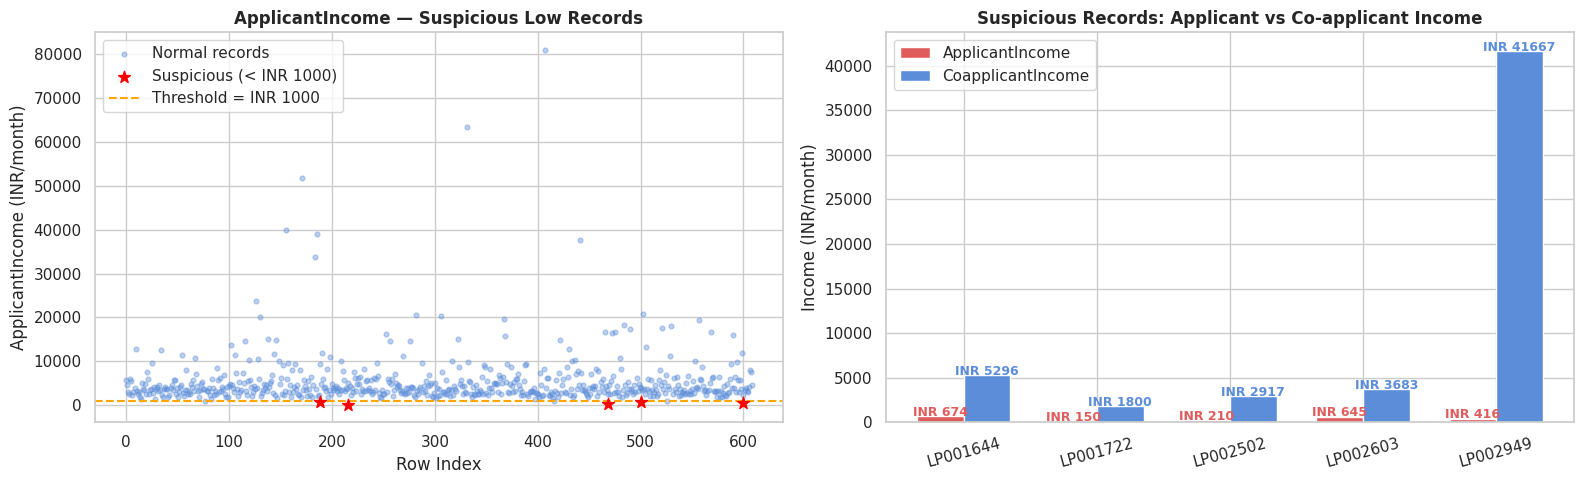


Observation:
  All 5 records show very high CoapplicantIncome relative to ApplicantIncome.
  These are consistent with data entry errors (missing zero) or dependent applicants.
  Decision: Remove all rows where ApplicantIncome < INR 1000/month.


In [105]:
# -----------------------------------------------------------------------
# Section 3d: Detect suspiciously low ApplicantIncome records
# Purpose : A monthly income of less than INR 1,000 is unrealistically
#           low for a loan applicant. Such records are likely caused by:
#             (a) Data entry errors (e.g. missing a zero: 150 instead of 1500)
#             (b) Cases where the co-applicant is the primary earner and
#                 the applicant figure was filled incorrectly.
#
#           Threshold chosen: INR 1,000 per month
#           This is below India's daily minimum wage rate (approx INR 400-500/day)
#           making a monthly figure of < INR 1,000 implausible.
#
# Visualisation 1 (Left) : Scatter plot marking suspicious records with a star.
# Visualisation 2 (Right): Side-by-side bar comparing applicant vs
#                          co-applicant income for the suspicious records.
# -----------------------------------------------------------------------

LOW_INCOME_THRESHOLD = 1000  # INR per month

low_income = df[df['ApplicantIncome'] < LOW_INCOME_THRESHOLD]
print(f'Records with ApplicantIncome < INR {LOW_INCOME_THRESHOLD}/month : {len(low_income)}')
print()
print(low_income[['Loan_ID', 'Gender', 'Married', 'Education', 'Self_Employed',
                   'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
                   'Loan_Amount_Term', 'Loan_Status']].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Left: Scatter plot highlighting suspicious records ---
normal = df[df['ApplicantIncome'] >= LOW_INCOME_THRESHOLD]
axes[0].scatter(range(len(normal)), normal['ApplicantIncome'],
                alpha=0.4, s=12, color='#5b8dd9', label='Normal records')
axes[0].scatter(low_income.index, low_income['ApplicantIncome'],
                alpha=1.0, s=80, color='red', marker='*',
                label=f'Suspicious (< INR {LOW_INCOME_THRESHOLD})', zorder=5)
axes[0].axhline(LOW_INCOME_THRESHOLD, color='orange', linestyle='--',
                linewidth=1.5, label=f'Threshold = INR {LOW_INCOME_THRESHOLD}')
axes[0].set_title('ApplicantIncome — Suspicious Low Records', fontweight='bold')
axes[0].set_ylabel('ApplicantIncome (INR/month)')
axes[0].set_xlabel('Row Index')
axes[0].legend()

# --- Right: Grouped bar chart for suspicious records only ---
labels = low_income['Loan_ID'].values
x = range(len(labels))
w = 0.35
axes[1].bar([i - w/2 for i in x], low_income['ApplicantIncome'],
            width=w, label='ApplicantIncome', color='#e05c5c')
axes[1].bar([i + w/2 for i in x], low_income['CoapplicantIncome'],
            width=w, label='CoapplicantIncome', color='#5b8dd9')
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(labels, rotation=15)
axes[1].set_title('Suspicious Records: Applicant vs Co-applicant Income', fontweight='bold')
axes[1].set_ylabel('Income (INR/month)')
axes[1].legend()
# Annotate bars with exact values
for i, (ai, ci) in enumerate(zip(low_income['ApplicantIncome'],
                                  low_income['CoapplicantIncome'])):
    axes[1].text(i - w/2, ai + 30, f'INR {ai}',
                 ha='center', fontsize=9, color='#e05c5c', fontweight='bold')
    axes[1].text(i + w/2, ci + 30, f'INR {ci:.0f}',
                 ha='center', fontsize=9, color='#5b8dd9', fontweight='bold')

plt.tight_layout()
plt.show()

print()
print('Observation:')
print(f'  All {len(low_income)} records show very high CoapplicantIncome relative to ApplicantIncome.')
print('  These are consistent with data entry errors (missing zero) or dependent applicants.')
print(f'  Decision: Remove all rows where ApplicantIncome < INR {LOW_INCOME_THRESHOLD}/month.')

In [106]:
# -----------------------------------------------------------------------
# Section 3e: Remove suspicious low-income records
# Purpose : Drop the 3 records identified in Section 3d from the DataFrame
#           before imputation so that they do not influence fill values.
#
#   Records removed:
#     LP001722 - ApplicantIncome = INR 150/month
#     LP002502 - ApplicantIncome = INR 210/month
#     LP002949 - ApplicantIncome = INR 416/month
#
# After removal, the minimum ApplicantIncome rises to a realistic value.
# -----------------------------------------------------------------------

rows_before = len(df)
df = df[df['ApplicantIncome'] >= LOW_INCOME_THRESHOLD].reset_index(drop=True)
rows_after  = len(df)

print('Low-income record removal:')
print(f'  Rows before : {rows_before}')
print(f'  Rows after  : {rows_after}')
print(f'  Removed     : {rows_before - rows_after} record(s)')
print()
print('Updated ApplicantIncome statistics:')
print(df['ApplicantIncome'].describe().round(2).to_string())

Low-income record removal:
  Rows before : 614
  Rows after  : 609
  Removed     : 5 record(s)

Updated ApplicantIncome statistics:
count      609.00
mean      5444.38
std       6117.26
min       1000.00
25%       2895.00
50%       3816.00
75%       5815.00
max      81000.00


---
## Section 4 — Distribution Visualisations Before Cleaning

Before applying any transformations, we examine the raw distributions of
all columns. This step:
- Confirms the shape (skewed vs. symmetric) of numeric features.
- Shows the frequency of each category in categorical columns.
- Box plots reveal the presence and severity of outliers visually.

These plots serve as the **before** baseline for comparison with post-cleaning distributions.

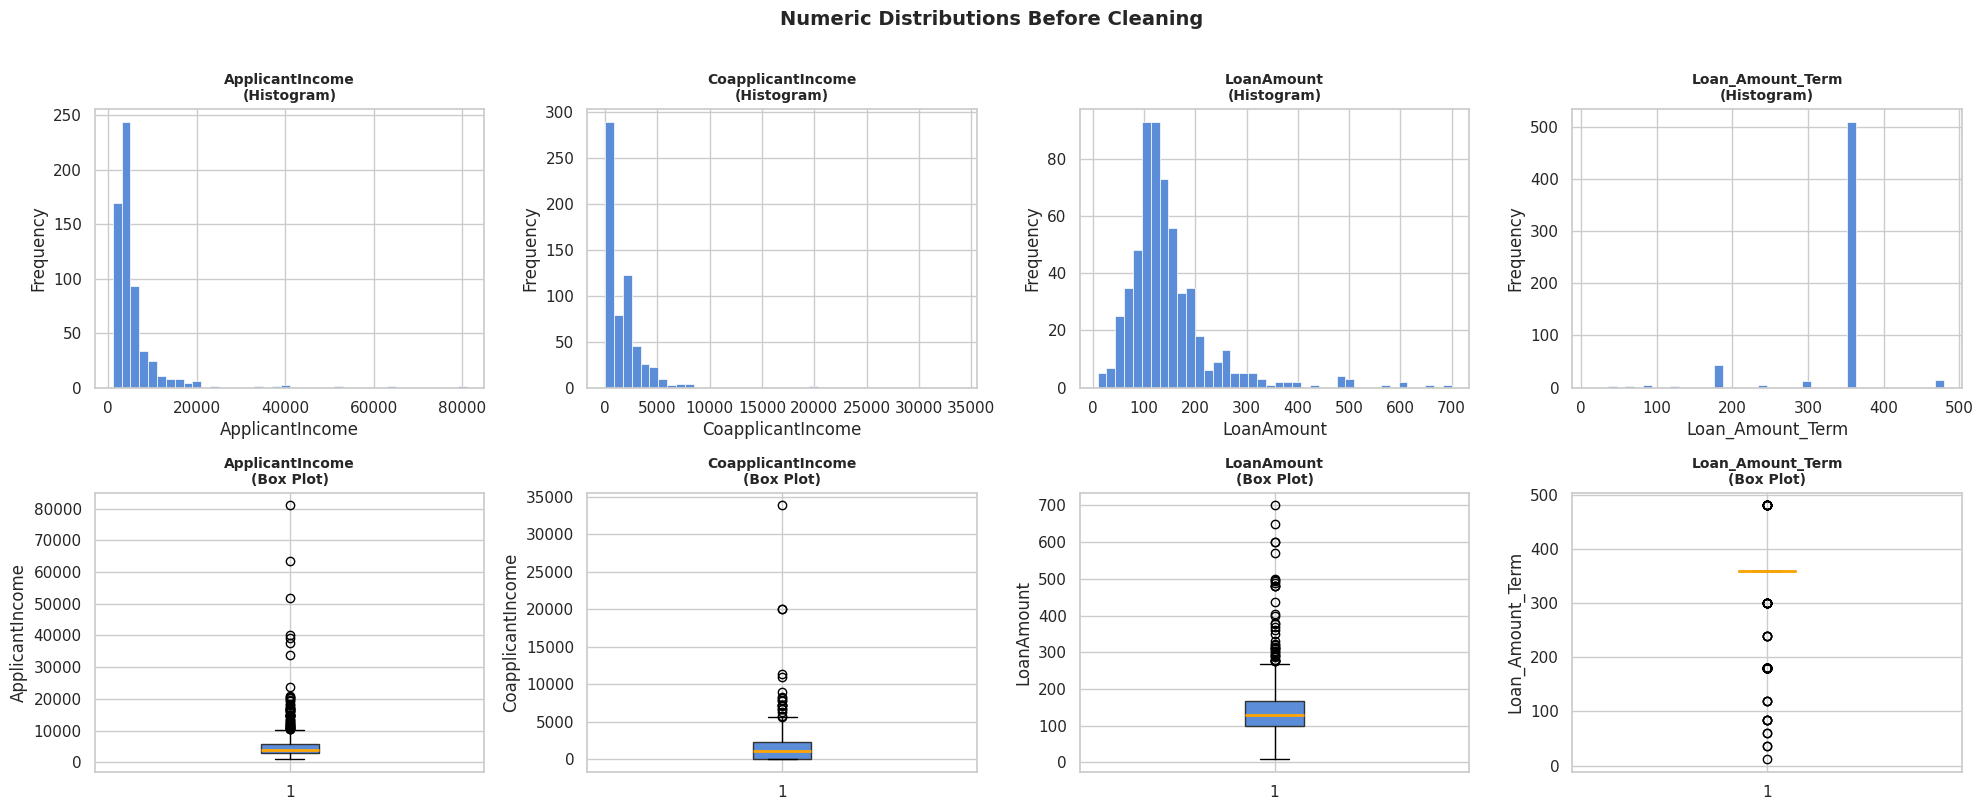

In [107]:
# -----------------------------------------------------------------------
# Section 4a: Histograms and box plots for numeric columns
# Purpose : Display the distribution shape and identify outliers for
#           the four main numeric features.
#
#   Row 1 (top)    : Histograms — show the frequency distribution.
#   Row 2 (bottom) : Box plots  — show quartiles and outlier points.
#
# Observations to look for:
#   - Right skew (long right tail) in income columns is common.
#   - Points beyond box plot whiskers are statistical outliers.
# -----------------------------------------------------------------------

num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for i, col in enumerate(num_cols):
    # Histogram
    axes[0, i].hist(df[col].dropna(), bins=40, color='#5b8dd9',
                    edgecolor='white', linewidth=0.5)
    axes[0, i].set_title(f'{col}\n(Histogram)', fontsize=10, fontweight='bold')
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel('Frequency')

    # Box plot
    axes[1, i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
                       boxprops=dict(facecolor='#5b8dd9', color='#333'),
                       medianprops=dict(color='orange', linewidth=2))
    axes[1, i].set_title(f'{col}\n(Box Plot)', fontsize=10, fontweight='bold')
    axes[1, i].set_ylabel(col)

plt.suptitle('Numeric Distributions Before Cleaning', fontsize=14,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

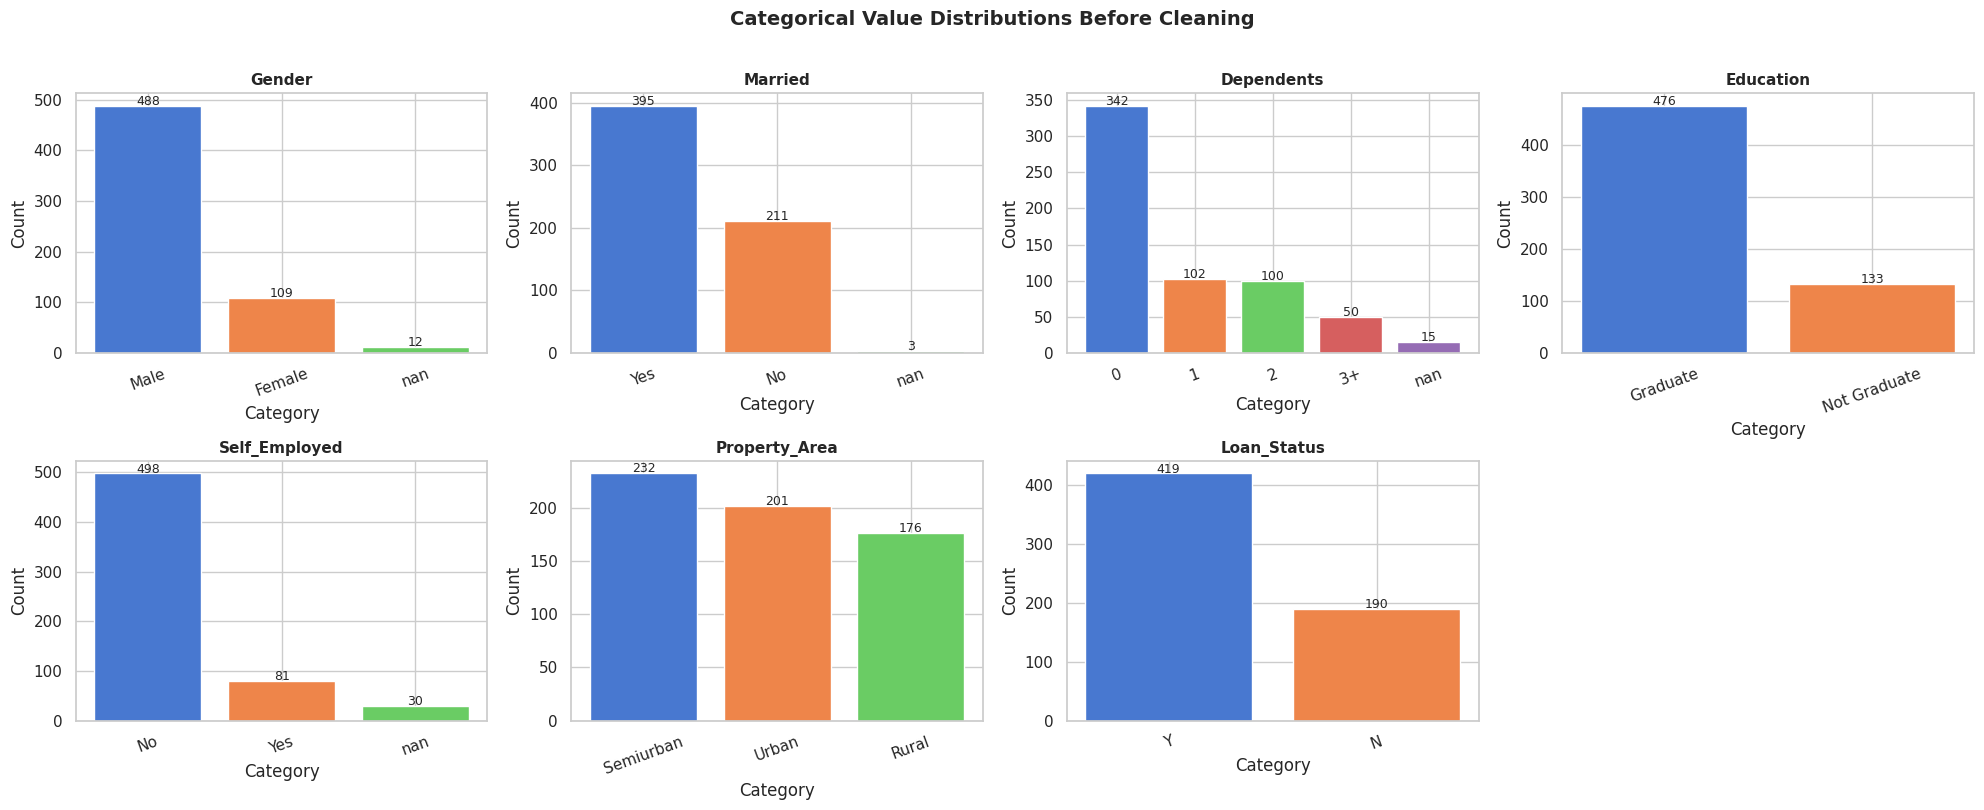

In [108]:
# -----------------------------------------------------------------------
# Section 4b: Bar charts for categorical columns
# Purpose : Show value frequency for each categorical column.
#           NaN is included in counts (shown as 'nan') to make missing
#           values visible in the chart.
# -----------------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()  # Flatten 2D array to 1D for easy iteration

for i, col in enumerate(cat_cols):
    counts = df[col].value_counts(dropna=False)  # Include NaN in counts
    axes[i].bar(counts.index.astype(str), counts.values,
                color=sns.color_palette('muted', len(counts)),
                edgecolor='white')
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Category')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=20)
    # Annotate each bar with its count
    for j, v in enumerate(counts.values):
        axes[i].text(j, v + 1, str(v), ha='center', fontsize=9)

axes[-1].set_visible(False)  # Hide the unused 8th subplot
plt.suptitle('Categorical Value Distributions Before Cleaning', fontsize=14,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## Section 5 — Missing Value Imputation

Imputation fills missing values with a statistically appropriate substitute
so that no information is lost by dropping rows.

### Imputation Strategy

| Column | Strategy | Reason |
|---|---|---|
| Gender | Mode | Categorical — the most frequent value is the best guess |
| Married | Mode | Categorical — the most frequent value is the best guess |
| Dependents | Mode | Categorical — the most frequent value is the best guess |
| Self_Employed | Mode | Categorical — the most frequent value is the best guess |
| Credit_History | Mode | Binary (0/1) — mode = 1.0 (majority have good credit) |
| LoanAmount | Median | Numeric, right-skewed — median is robust to outliers |
| Loan_Amount_Term | Mode | Most loans are 360 months; mode is representative |

**Why not Mean for LoanAmount?**
Income and loan amount distributions are right-skewed (a small number of very
high values inflate the mean). Using the **median** avoids introducing upward bias
into the imputed values.

In [109]:
# -----------------------------------------------------------------------
# Section 5: Impute missing values
# Purpose : Fill all NaN values using the strategies defined above.
#           A copy of the cleaned DataFrame is created to preserve the
#           original raw data in 'df' for reference.
#
# After this cell, df_clean should have zero missing values.
# -----------------------------------------------------------------------

df_clean = df.copy()  # Work on a copy to avoid modifying the original

# --- Categorical columns: fill with MODE ---
cat_fill = ['Gender', 'Married', 'Dependents', 'Self_Employed']
print('Categorical imputation (Mode):')
for col in cat_fill:
    mode_val = df_clean[col].mode()[0]     # Mode = most frequent value
    n_filled = df_clean[col].isnull().sum()  # Count nulls before filling
    df_clean[col].fillna(mode_val, inplace=True)
    print(f'  {col:18s} : filled {n_filled:2d} null(s) with mode = "{mode_val}"')

# --- Credit_History: fill with MODE (binary column) ---
ch_mode = df_clean['Credit_History'].mode()[0]
n_ch    = df_clean['Credit_History'].isnull().sum()
df_clean['Credit_History'].fillna(ch_mode, inplace=True)
print(f'\nBinary imputation (Mode):')
print(f'  {"Credit_History":18s} : filled {n_ch:2d} null(s) with mode = {ch_mode}')

# --- LoanAmount: fill with MEDIAN (robust to skew) ---
la_median = df_clean['LoanAmount'].median()
n_la      = df_clean['LoanAmount'].isnull().sum()
df_clean['LoanAmount'].fillna(la_median, inplace=True)
print(f'\nNumeric imputation (Median):')
print(f'  {"LoanAmount":18s} : filled {n_la:2d} null(s) with median = {la_median}')

# --- Loan_Amount_Term: fill with MODE ---
lat_mode = df_clean['Loan_Amount_Term'].mode()[0]
n_lat    = df_clean['Loan_Amount_Term'].isnull().sum()
df_clean['Loan_Amount_Term'].fillna(lat_mode, inplace=True)
print(f'\nNumeric imputation (Mode):')
print(f'  {"Loan_Amount_Term":18s} : filled {n_lat:2d} null(s) with mode = {lat_mode}')

# --- Verification ---
remaining = df_clean.isnull().sum().sum()
print(f'\nRemaining null values after imputation: {remaining}')
if remaining == 0:
    print('All missing values have been handled.')
else:
    print('WARNING: Some null values still remain. Review the code above.')

Categorical imputation (Mode):
  Gender             : filled 12 null(s) with mode = "Male"
  Married            : filled  3 null(s) with mode = "Yes"
  Dependents         : filled 15 null(s) with mode = "0"
  Self_Employed      : filled 30 null(s) with mode = "No"

Binary imputation (Mode):
  Credit_History     : filled 49 null(s) with mode = 1.0

Numeric imputation (Median):
  LoanAmount         : filled 22 null(s) with median = 128.0

Numeric imputation (Mode):
  Loan_Amount_Term   : filled 14 null(s) with mode = 360.0

Remaining null values after imputation: 0
All missing values have been handled.


---
## Section 6 — Outlier Detection and Removal (IQR Method)

### Why Remove Outliers?
Extreme values in income or loan amount columns can:
- Skew model training by giving disproportionate influence to rare observations.
- Distort distance-based algorithms (KNN, SVM, K-Means).
- Inflate feature importance in tree-based models.

### IQR (Interquartile Range) Method
The IQR method is a non-parametric, robust technique for identifying outliers.

```
IQR   = Q3 - Q1
Lower fence = Q1 - 1.5 x IQR
Upper fence = Q3 + 1.5 x IQR
Records outside these fences are considered outliers and are removed.
```

### Columns Checked
| Column | Reason |
|---|---|
| ApplicantIncome | Highly right-skewed; some incomes exceed INR 80,000/month |
| CoapplicantIncome | Many zeros combined with some very large values |
| LoanAmount | Loan amounts vary widely; extreme values may reflect data errors |

In [110]:
# -----------------------------------------------------------------------
# Section 6a: Calculate IQR bounds and count outliers
# Purpose : For each column, compute Q1, Q3, IQR, and the lower/upper
#           fences. Count records outside those fences.
#           Store the bounds in a dictionary for use in removal.
# -----------------------------------------------------------------------

outlier_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']

print(f'{"Column":<22} {"Q1":>8} {"Q3":>8} {"IQR":>8} {"Lower":>10} {"Upper":>10} {"Outliers":>10}')
print('-' * 80)

bounds = {}
for col in outlier_cols:
    Q1  = df_clean[col].quantile(0.25)
    Q3  = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lo  = Q1 - 1.5 * IQR
    hi  = Q3 + 1.5 * IQR
    n   = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    bounds[col] = (lo, hi)
    print(f'{col:<22} {Q1:>8.1f} {Q3:>8.1f} {IQR:>8.1f} {lo:>10.1f} {hi:>10.1f} {n:>10}')

Column                       Q1       Q3      IQR      Lower      Upper   Outliers
--------------------------------------------------------------------------------
ApplicantIncome          2895.0   5815.0   2920.0    -1485.0    10195.0         50
CoapplicantIncome           0.0   2254.0   2254.0    -3381.0     5635.0         19
LoanAmount                100.0    164.0     64.0        4.0      260.0         40


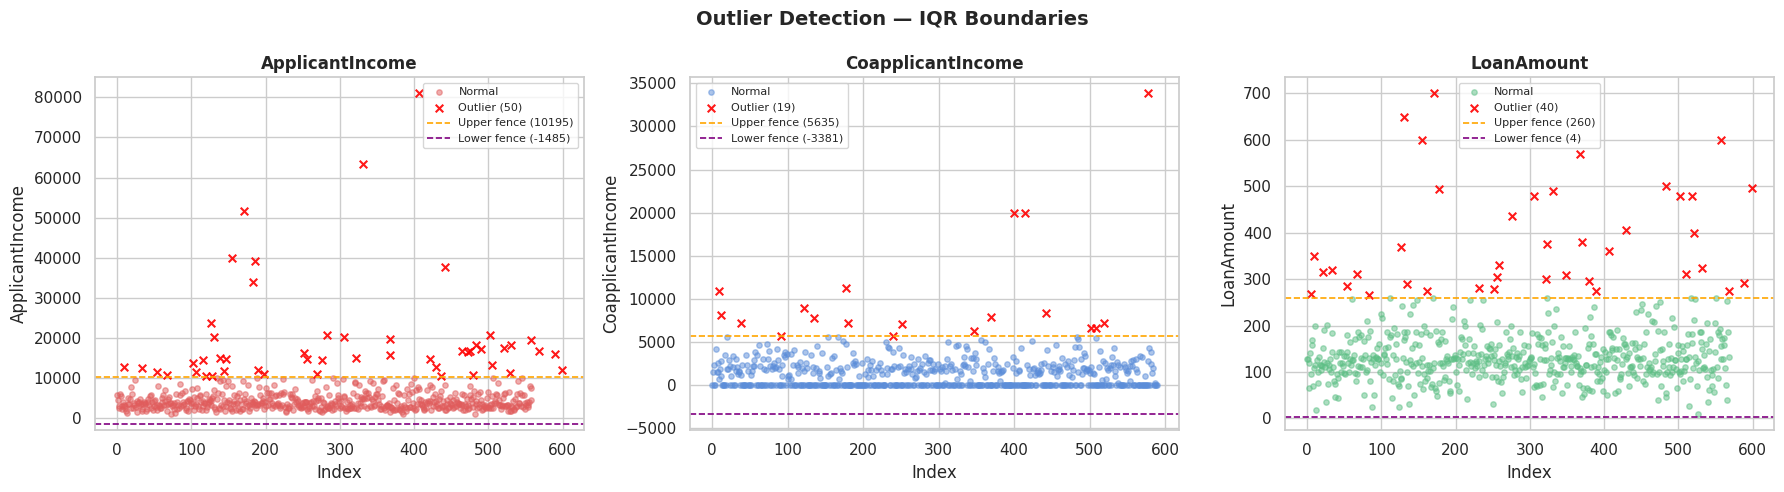

In [111]:
# -----------------------------------------------------------------------
# Section 6b: Visualise outliers before removal
# Purpose : Scatter plot for each column. Normal records are shown in blue,
#           outliers are marked with a red X. Orange and purple dashed
#           lines indicate the IQR upper and lower fences respectively.
# -----------------------------------------------------------------------

colors = ['#e05c5c', '#5b8dd9', '#5dbf85']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(outlier_cols):
    lo, hi = bounds[col]
    data   = df_clean[col]
    mask   = (data < lo) | (data > hi)  # Boolean mask: True = outlier

    # Plot normal points
    axes[i].scatter(range(len(data[~mask])), data[~mask],
                    alpha=0.5, s=15, color=colors[i], label='Normal')
    # Plot outlier points
    axes[i].scatter(data[mask].index, data[mask],
                    alpha=0.9, s=30, color='red', marker='x',
                    label=f'Outlier ({mask.sum()})')
    # Draw fence lines
    axes[i].axhline(hi, color='orange', linestyle='--', linewidth=1.2,
                    label=f'Upper fence ({hi:.0f})')
    axes[i].axhline(lo, color='purple', linestyle='--', linewidth=1.2,
                    label=f'Lower fence ({lo:.0f})')
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_ylabel(col)
    axes[i].set_xlabel('Index')
    axes[i].legend(fontsize=8)

plt.suptitle('Outlier Detection — IQR Boundaries', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [112]:
# -----------------------------------------------------------------------
# Section 6c: Remove outlier records
# Purpose : Build a single boolean mask that is True for rows where ALL
#           three columns are within their IQR fences.
#           Rows where any column is outside its fence are dropped.
#
# Note: Applying all three conditions simultaneously avoids repeatedly
# re-indexing the DataFrame and is more efficient than filtering one
# column at a time.
# -----------------------------------------------------------------------

rows_before = len(df_clean)

# Start with all rows marked as 'keep' (True)
mask_keep = pd.Series([True] * len(df_clean), index=df_clean.index)

for col in outlier_cols:
    lo, hi    = bounds[col]
    mask_keep = mask_keep & df_clean[col].between(lo, hi)  # AND: must satisfy all columns

df_clean  = df_clean[mask_keep].reset_index(drop=True)
rows_after = len(df_clean)

print('Outlier removal summary:')
print(f'  Rows before removal : {rows_before}')
print(f'  Rows after  removal : {rows_after}')
print(f'  Rows removed        : {rows_before - rows_after}')

Outlier removal summary:
  Rows before removal : 609
  Rows after  removal : 529
  Rows removed        : 80


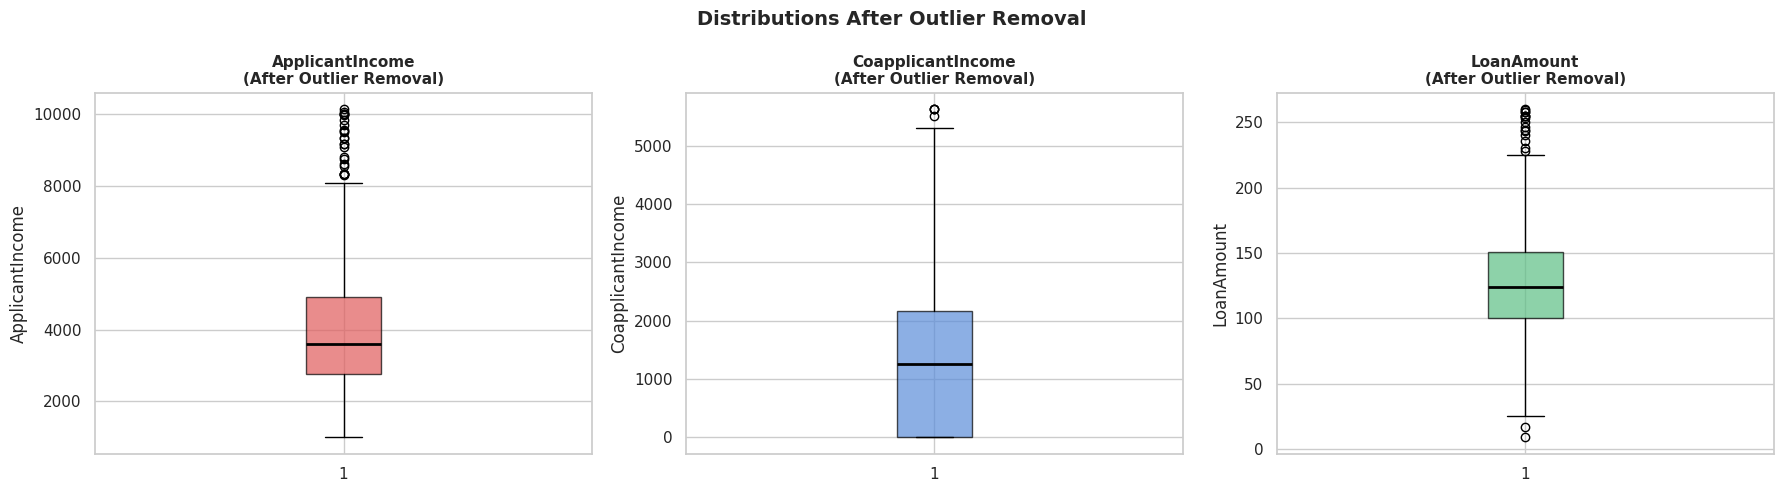

In [113]:
# -----------------------------------------------------------------------
# Section 6d: Box plots after outlier removal
# Purpose : Confirm that outliers have been removed by comparing box plots
#           to those in Section 4a. Whiskers should now be much shorter
#           and no extreme points should appear beyond them.
# -----------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(outlier_cols):
    axes[i].boxplot(df_clean[col], vert=True, patch_artist=True,
                    boxprops=dict(facecolor=colors[i], alpha=0.7),
                    medianprops=dict(color='black', linewidth=2))
    axes[i].set_title(f'{col}\n(After Outlier Removal)', fontsize=11, fontweight='bold')
    axes[i].set_ylabel(col)

plt.suptitle('Distributions After Outlier Removal', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section 7 — Feature Engineering

New features are derived to capture **combined financial strength** and
**loan burden relative to income** — signals that a bank loan officer
would naturally consider when evaluating an application.

| New Feature | Formula | Intuition |
|---|---|---|
| TotalIncome | ApplicantIncome + CoapplicantIncome | Household combined monthly income |
| Log_ApplicantIncome | log(1 + ApplicantIncome) | Reduces right skew |
| Log_CoapplicantIncome | log(1 + CoapplicantIncome) | Reduces right skew |
| Log_LoanAmount | log(1 + LoanAmount) | Reduces right skew |
| Log_TotalIncome | log(1 + TotalIncome) | Reduces right skew |
| EMI | LoanAmount / Loan_Amount_Term | Estimated monthly instalment |
| LoanToIncome | LoanAmount / (TotalIncome + 1) | Debt-to-income ratio |
| BalanceIncome | TotalIncome - (EMI * 1000) | Disposable income after loan payments |

**Why log(1 + x) instead of log(x)?**
Adding 1 before taking the logarithm prevents a domain error when x = 0
(which occurs in CoapplicantIncome for single-income applicants).

In [114]:
# -----------------------------------------------------------------------
# Section 7a: Create derived features
# Purpose : Add new columns to df_clean that capture financial ratios
#           and log-transformed versions of skewed numeric columns.
# -----------------------------------------------------------------------

# Total household income
df_clean['TotalIncome'] = df_clean['ApplicantIncome'] + df_clean['CoapplicantIncome']

# Log transforms to reduce right skew (log1p = log(1+x), safe for zero values)
df_clean['Log_ApplicantIncome']   = np.log1p(df_clean['ApplicantIncome'])
df_clean['Log_CoapplicantIncome'] = np.log1p(df_clean['CoapplicantIncome'])
df_clean['Log_LoanAmount']        = np.log1p(df_clean['LoanAmount'])
df_clean['Log_TotalIncome']       = np.log1p(df_clean['TotalIncome'])

# Loan burden features
df_clean['EMI']           = df_clean['LoanAmount'] / df_clean['Loan_Amount_Term']
df_clean['LoanToIncome']  = df_clean['LoanAmount'] / (df_clean['TotalIncome'] + 1)
df_clean['BalanceIncome'] = df_clean['TotalIncome'] - (df_clean['EMI'] * 1000)

new_feats = ['TotalIncome', 'Log_ApplicantIncome', 'Log_CoapplicantIncome',
             'Log_LoanAmount', 'Log_TotalIncome', 'EMI', 'LoanToIncome', 'BalanceIncome']

print('New features created:')
print(df_clean[new_feats].describe().T.to_string())

New features created:
                       count         mean          std          min          25%          50%          75%           max
TotalIncome            529.0  5369.636900  1989.903418  1442.000000  3900.000000  5000.000000  6406.000000  13746.000000
Log_ApplicantIncome    529.0     8.222582     0.424712     6.908755     7.926242     8.189245     8.496174      9.224243
Log_CoapplicantIncome  529.0     4.311544     3.795692     0.000000     0.000000     7.131699     7.681560      8.635154
Log_LoanAmount         529.0     4.774959     0.403636     2.302585     4.615121     4.828314     5.023881      5.564520
Log_TotalIncome        529.0     8.522279     0.367599     7.274480     8.268988     8.517393     8.765146      9.528576
EMI                    529.0     0.412789     0.472358     0.025000     0.277778     0.355556     0.444444      9.250000
LoanToIncome           529.0     0.024629     0.007995     0.003783     0.020179     0.024474     0.028249      0.082685
BalanceInc

Skewness comparison (lower absolute value = more symmetric):
                   Before (Original)  After (Log Transform)
ApplicantIncome               1.2088                 0.1239
CoapplicantIncome             0.8157                -0.2367
LoanAmount                    0.4574                -1.3132


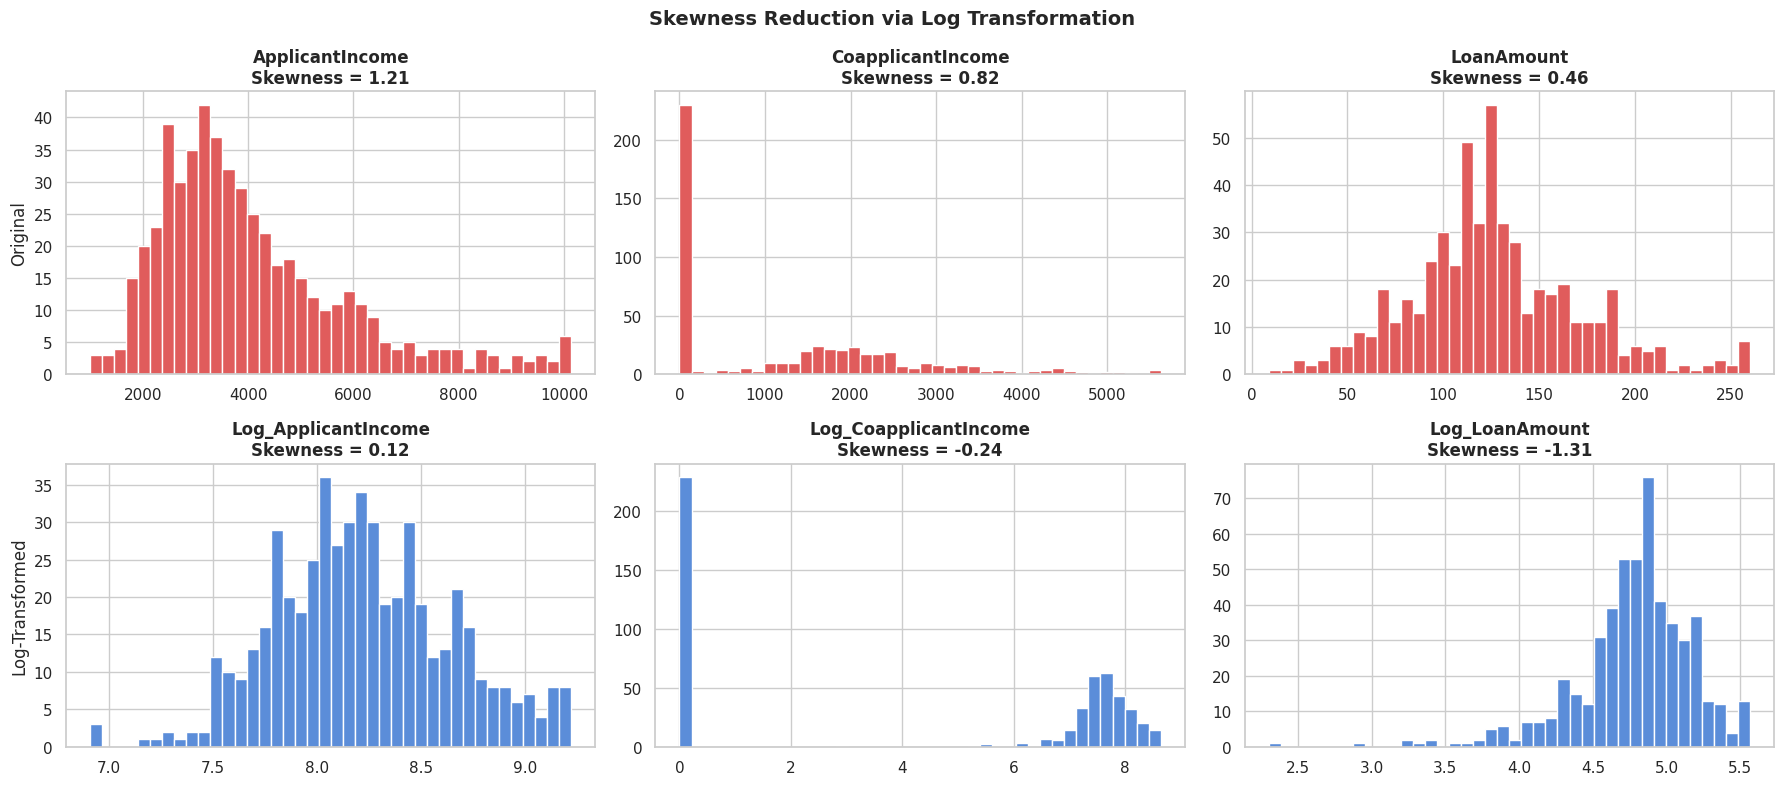

In [115]:
# -----------------------------------------------------------------------
# Section 7b: Skewness comparison before and after log transform
# Purpose : Quantify and visualise how much the log transform reduces
#           skewness in the three main numeric columns.
#
#   Skewness close to 0 indicates a more symmetric distribution,
#   which is preferred by many machine learning algorithms.
#
#   Top row    : Histograms of original (skewed) values.
#   Bottom row : Histograms of log-transformed (less skewed) values.
# -----------------------------------------------------------------------

cols_raw = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']
cols_log = ['Log_ApplicantIncome', 'Log_CoapplicantIncome', 'Log_LoanAmount']

skew_compare = pd.DataFrame({
    'Before (Original)'    : [df_clean[c].skew() for c in cols_raw],
    'After (Log Transform)': [df_clean[c].skew() for c in cols_log]
}, index=cols_raw)

print('Skewness comparison (lower absolute value = more symmetric):')
print(skew_compare.round(4).to_string())

fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for i in range(3):
    # Original distribution
    axes[0, i].hist(df_clean[cols_raw[i]], bins=40,
                    color='#e05c5c', edgecolor='white')
    axes[0, i].set_title(f'{cols_raw[i]}\nSkewness = {df_clean[cols_raw[i]].skew():.2f}',
                         fontweight='bold')

    # Log-transformed distribution
    axes[1, i].hist(df_clean[cols_log[i]], bins=40,
                    color='#5b8dd9', edgecolor='white')
    axes[1, i].set_title(f'{cols_log[i]}\nSkewness = {df_clean[cols_log[i]].skew():.2f}',
                         fontweight='bold')

axes[0, 0].set_ylabel('Original', fontsize=12)
axes[1, 0].set_ylabel('Log-Transformed', fontsize=12)

plt.suptitle('Skewness Reduction via Log Transformation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section 8 — Encoding Categorical Variables

Machine learning models require all features to be in numeric format.
Three encoding strategies are used based on the nature of each column:

| Encoding Type | Applied To | Reason |
|---|---|---|
| Label Encoding (0/1) | Gender, Married, Education, Self_Employed, Loan_Status | Binary categories — 0 and 1 is sufficient |
| Ordinal Encoding | Dependents | Natural order exists: 0 < 1 < 2 < 3+ |
| One-Hot Encoding | Property_Area | 3 unordered categories — avoids implying a false numerical rank |

**Why not label-encode Property_Area?**
Label encoding Urban=0, Semiurban=1, Rural=2 would imply that Rural > Urban
numerically, which has no real meaning. One-hot encoding creates separate binary
columns that avoid this issue.

In [116]:
# -----------------------------------------------------------------------
# Section 8: Encode categorical variables
# Purpose : Convert all non-numeric columns to numeric representations
#           that machine learning models can process.
#
#   Step 1: Label-encode binary categorical columns.
#   Step 2: Ordinal-encode Dependents (0,1,2,3+) -> (0,1,2,3).
#   Step 3: One-hot encode Property_Area into three binary columns.
# -----------------------------------------------------------------------

df_encoded = df_clean.copy()  # Preserve df_clean for the cleaned output CSV

# --- Step 1: Label encode binary columns ---
binary_cols = ['Gender', 'Married', 'Education', 'Self_Employed', 'Loan_Status']
le = LabelEncoder()

print('Label Encoding (binary columns):')
for col in binary_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f'  {col:18s} -> {mapping}')

# --- Step 2: Ordinal encode Dependents ---
dep_map = {'0': 0, '1': 1, '2': 2, '3+': 3}
df_encoded['Dependents'] = df_encoded['Dependents'].map(dep_map)
print(f'\nOrdinal Encoding:')
print(f'  {"Dependents":18s} -> {dep_map}')

# --- Step 3: One-hot encode Property_Area ---
df_encoded = pd.get_dummies(df_encoded, columns=['Property_Area'], drop_first=False)
ohe_cols   = [c for c in df_encoded.columns if 'Property_Area' in c]
print(f'\nOne-Hot Encoding:')
print(f'  Property_Area -> {ohe_cols}')

print('\nEncoding complete. Dataset shape:', df_encoded.shape)

Label Encoding (binary columns):
  Gender             -> {'Female': np.int64(0), 'Male': np.int64(1)}
  Married            -> {'No': np.int64(0), 'Yes': np.int64(1)}
  Education          -> {'Graduate': np.int64(0), 'Not Graduate': np.int64(1)}
  Self_Employed      -> {'No': np.int64(0), 'Yes': np.int64(1)}
  Loan_Status        -> {'N': np.int64(0), 'Y': np.int64(1)}

Ordinal Encoding:
  Dependents         -> {'0': 0, '1': 1, '2': 2, '3+': 3}

One-Hot Encoding:
  Property_Area -> ['Property_Area_Rural', 'Property_Area_Semiurban', 'Property_Area_Urban']

Encoding complete. Dataset shape: (529, 23)


---
## Section 9 — Feature Scaling

**StandardScaler** (Z-score normalisation) is applied to all numeric columns.

```
z = (x - mean) / standard_deviation
```

After scaling: mean = 0 and standard deviation = 1 for every scaled feature.

### Why Scale?
- Prevents high-magnitude features (e.g. ApplicantIncome in thousands) from
  dominating distance-based algorithms (KNN, SVM, K-Means).
- Required for gradient-descent-based models (Logistic Regression, Neural Networks)
  to converge efficiently.
- Tree-based models (Random Forest, XGBoost) are scale-invariant, but scaling
  does not hurt them either.

### Loan_ID
`Loan_ID` is a unique identifier with no predictive value. It is dropped before
scaling to avoid including meaningless data in the model.

In [117]:
# -----------------------------------------------------------------------
# Section 9: Scale numeric features
# Purpose : Apply StandardScaler to all continuous numeric columns so
#           that every feature has mean=0 and std=1.
#
#   Loan_ID is dropped first because it is a text identifier,
#   not a predictive feature.
#
#   Boolean columns created by one-hot encoding are cast to int
#   before scaling to ensure consistent numeric types.
# -----------------------------------------------------------------------

# Drop Loan_ID — it is a record identifier, not a model feature
df_encoded.drop(columns=['Loan_ID'], inplace=True)

# Convert boolean OHE columns to integer (0/1) before scaling
bool_cols = df_encoded.select_dtypes(include='bool').columns.tolist()
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

# Columns to scale (all continuous numeric features)
scale_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
              'Loan_Amount_Term', 'TotalIncome', 'EMI',
              'LoanToIncome', 'BalanceIncome',
              'Log_ApplicantIncome', 'Log_CoapplicantIncome',
              'Log_LoanAmount', 'Log_TotalIncome']

scaler = StandardScaler()
df_encoded[scale_cols] = scaler.fit_transform(df_encoded[scale_cols])

print('Scaling complete. Verification (mean and std after scaling):')
print(df_encoded[scale_cols].describe().T[['mean', 'std']].round(4).to_string())

Scaling complete. Verification (mean and std after scaling):
                       mean     std
ApplicantIncome         0.0  1.0009
CoapplicantIncome      -0.0  1.0009
LoanAmount             -0.0  1.0009
Loan_Amount_Term        0.0  1.0009
TotalIncome             0.0  1.0009
EMI                    -0.0  1.0009
LoanToIncome            0.0  1.0009
BalanceIncome           0.0  1.0009
Log_ApplicantIncome    -0.0  1.0009
Log_CoapplicantIncome  -0.0  1.0009
Log_LoanAmount          0.0  1.0009
Log_TotalIncome         0.0  1.0009


---
## Section 10 — Correlation Analysis

Correlation analysis measures the linear relationship between every pair of features.

- **Values close to +1**: strong positive correlation.
- **Values close to -1**: strong negative correlation.
- **Values close to 0**: little or no linear relationship.

Two plots are produced:
1. **Full correlation heatmap** — lower triangle only to avoid redundancy.
2. **Target correlation bar chart** — shows how strongly each feature correlates
   with the target variable `Loan_Status`.

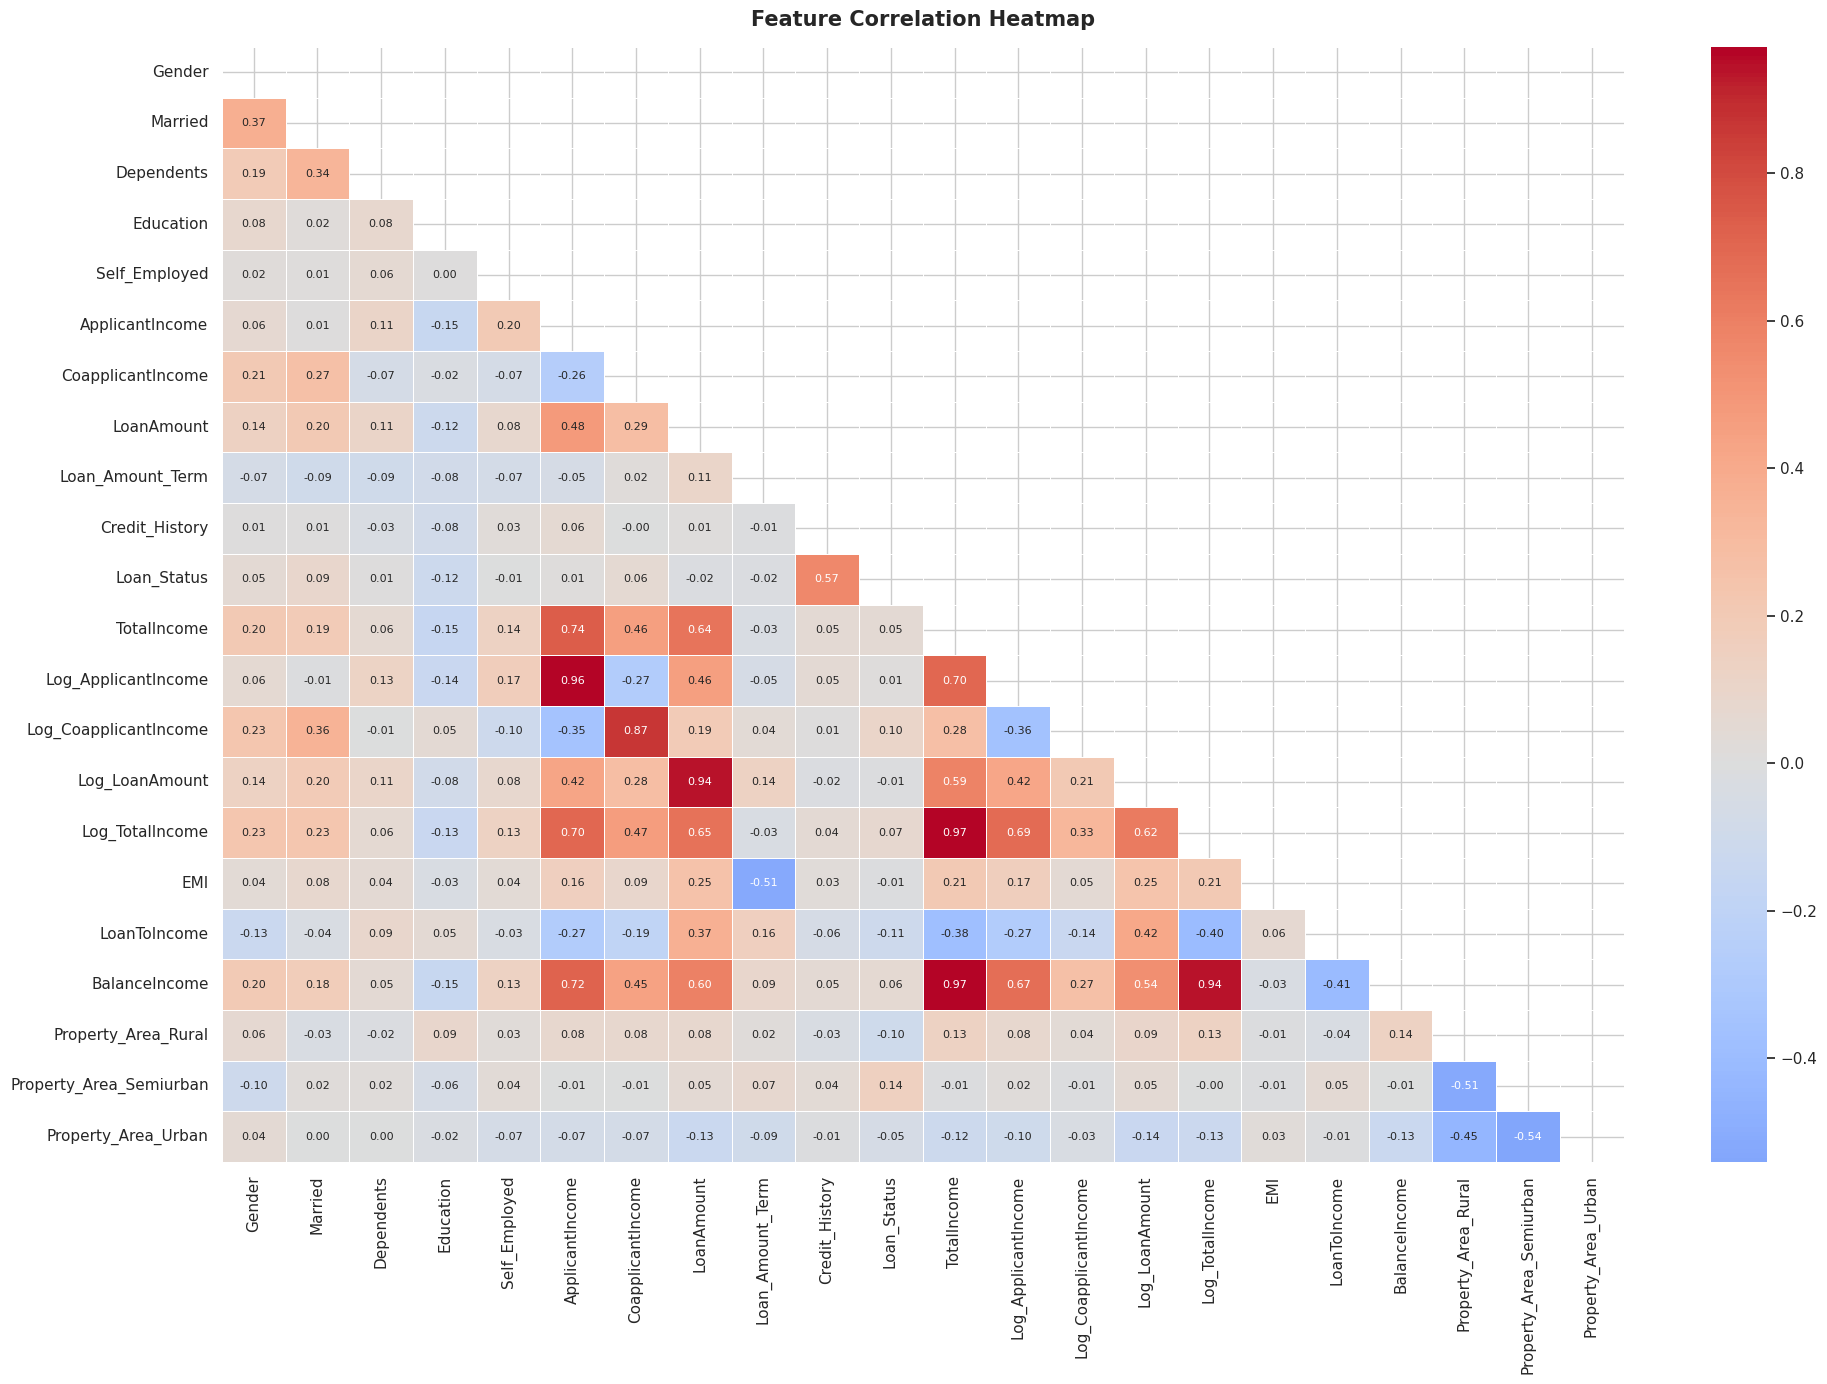

In [118]:
# -----------------------------------------------------------------------
# Section 10a: Full correlation heatmap
# Purpose : Display pairwise Pearson correlation coefficients for all
#           features in the preprocessed dataset.
#
#   Upper triangle is masked to reduce visual clutter since the matrix
#   is symmetric (corr(A,B) == corr(B,A)).
#
#   Color scale: Blue = negative correlation, Red = positive correlation.
# -----------------------------------------------------------------------

corr = df_encoded.corr()  # Compute Pearson correlation matrix

plt.figure(figsize=(20, 14))
mask = np.triu(np.ones_like(corr, dtype=bool))  # Mask upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.4, linecolor='white',
            annot_kws={'size': 8})
plt.title('Feature Correlation Heatmap', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

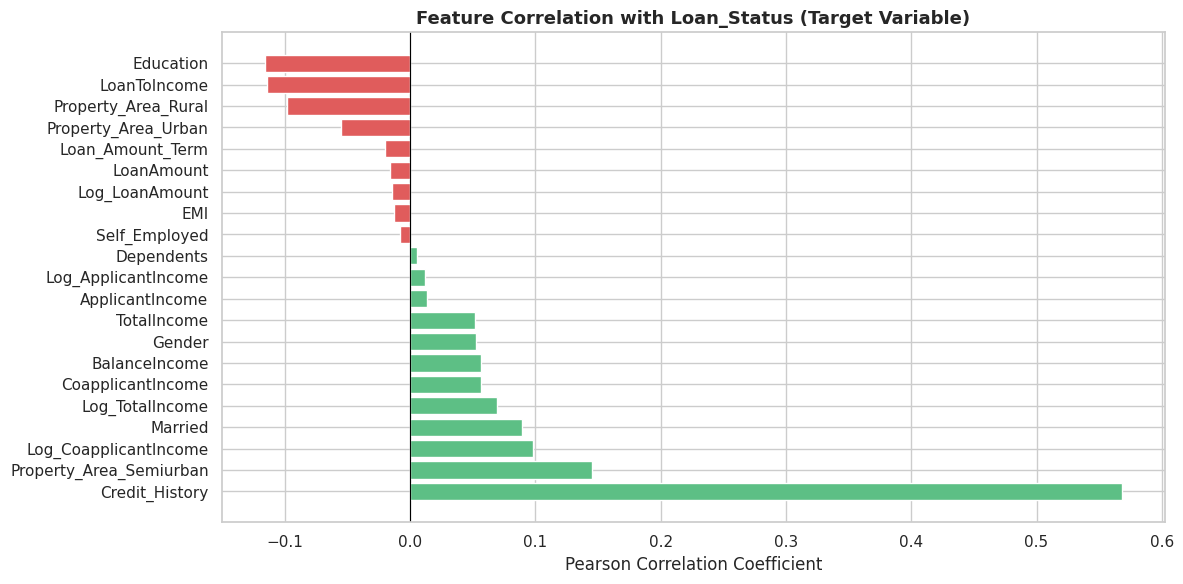

Correlation values with Loan_Status:
Credit_History             0.5681
Property_Area_Semiurban    0.1448
Log_CoapplicantIncome      0.0980
Married                    0.0890
Log_TotalIncome            0.0692
CoapplicantIncome          0.0563
BalanceIncome              0.0563
Gender                     0.0527
TotalIncome                0.0520
ApplicantIncome            0.0138
Log_ApplicantIncome        0.0121
Dependents                 0.0057
Self_Employed             -0.0081
EMI                       -0.0130
Log_LoanAmount            -0.0143
LoanAmount                -0.0161
Loan_Amount_Term          -0.0201
Property_Area_Urban       -0.0549
Property_Area_Rural       -0.0980
LoanToIncome              -0.1146
Education                 -0.1161


In [119]:
# -----------------------------------------------------------------------
# Section 10b: Correlation with target variable (Loan_Status)
# Purpose : Rank all features by their absolute correlation with the
#           target variable. This gives an initial indication of which
#           features are most predictive.
#
#   Green bars : positive correlation with Loan_Status (approval).
#   Red bars   : negative correlation with Loan_Status (rejection).
# -----------------------------------------------------------------------

target_corr = corr['Loan_Status'].drop('Loan_Status').sort_values(ascending=False)

plt.figure(figsize=(12, 6))
bar_colors = ['#5dbf85' if v >= 0 else '#e05c5c' for v in target_corr]
plt.barh(target_corr.index, target_corr.values, color=bar_colors, edgecolor='white')
plt.axvline(0, color='black', linewidth=0.8)  # Zero line for reference
plt.xlabel('Pearson Correlation Coefficient')
plt.title('Feature Correlation with Loan_Status (Target Variable)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Correlation values with Loan_Status:')
print(target_corr.round(4).to_string())

---
## Section 11 — Final Summary and Export

### Preprocessing Pipeline

```
Raw Data (614 rows x 13 columns)
        |
        v
[Step 1] Remove suspicious low-income records (ApplicantIncome < INR 1,000/month)
         Result: 609 rows
        |
        v
[Step 2] Impute missing values
         - Categorical columns  -> Mode
         - LoanAmount           -> Median
         - Loan_Amount_Term     -> Mode
         - Credit_History       -> Mode
         Result: 0 null values remaining
        |
        v
[Step 3] Remove IQR outliers
         Columns: ApplicantIncome, CoapplicantIncome, LoanAmount
         Result: 529 rows
        |
        v
[Step 4] Feature Engineering
         Added: TotalIncome, EMI, LoanToIncome, BalanceIncome,
                Log_ApplicantIncome, Log_CoapplicantIncome,
                Log_LoanAmount, Log_TotalIncome
        |
        v
[Step 5] Encode categorical variables
         Binary     -> Label Encoding (0/1)
         Dependents -> Ordinal Encoding (0,1,2,3)
         Property_Area -> One-Hot Encoding (3 new columns)
        |
        v
[Step 6] Scale numeric features
         StandardScaler: mean=0, std=1 for all continuous features
        |
        v
  Loan_Data_Cleaned.csv         (human-readable, original scale)
  Loan_Data_Preprocessed.csv   (model-ready, encoded and scaled)
```

In [120]:
# -----------------------------------------------------------------------
# Section 11a: Final dataset verification
# Purpose : Confirm the preprocessed dataset has:
#   - Zero remaining null values.
#   - The expected number of rows after all cleaning steps.
#   - The expected number of columns after feature engineering and encoding.
# -----------------------------------------------------------------------

# Assert that no null values remain — raises an error if check fails
assert df_encoded.isnull().sum().sum() == 0, 'ERROR: Null values still present in df_encoded.'
print('Verification passed: No null values in the final dataset.')

print('\nFinal dataset shape:', df_encoded.shape)
print('\nColumn list:')
for i, col in enumerate(df_encoded.columns, 1):
    print(f'  {i:2d}. {col}')

Verification passed: No null values in the final dataset.

Final dataset shape: (529, 22)

Column list:
   1. Gender
   2. Married
   3. Dependents
   4. Education
   5. Self_Employed
   6. ApplicantIncome
   7. CoapplicantIncome
   8. LoanAmount
   9. Loan_Amount_Term
  10. Credit_History
  11. Loan_Status
  12. TotalIncome
  13. Log_ApplicantIncome
  14. Log_CoapplicantIncome
  15. Log_LoanAmount
  16. Log_TotalIncome
  17. EMI
  18. LoanToIncome
  19. BalanceIncome
  20. Property_Area_Rural
  21. Property_Area_Semiurban
  22. Property_Area_Urban


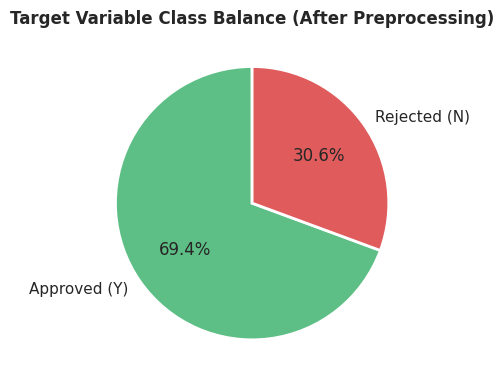

Class distribution:
  Y : 367 records (69.4%)
  N : 162 records (30.6%)


In [121]:
# -----------------------------------------------------------------------
# Section 11b: Target variable class balance
# Purpose : Check the ratio of approved vs rejected loans in the cleaned
#           dataset. Class imbalance (e.g. 90% approved / 10% rejected)
#           would require special handling (e.g. SMOTE, class weights)
#           before model training.
# -----------------------------------------------------------------------

# Note: After label encoding, Loan_Status values are numeric (0 or 1).
# Use the original df_clean which still has Y/N labels for readability.
vc  = df_clean['Loan_Status'].value_counts()
pct = vc / vc.sum() * 100

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.pie(vc.values,
       labels=['Approved (Y)', 'Rejected (N)'],
       autopct='%1.1f%%',
       colors=['#5dbf85', '#e05c5c'],
       startangle=90,
       wedgeprops=dict(edgecolor='white', linewidth=2))
ax.set_title('Target Variable Class Balance (After Preprocessing)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('Class distribution:')
for label, count, percent in zip(vc.index, vc.values, pct.values):
    print(f'  {label} : {count} records ({percent:.1f}%)')

In [122]:
# -----------------------------------------------------------------------
# Section 11c: Preview of final preprocessed dataset
# Purpose : Display the first 5 rows of the fully preprocessed dataset
#           to confirm it looks correct before saving.
# -----------------------------------------------------------------------

print('First 5 rows of the preprocessed dataset:')
df_encoded.head()

First 5 rows of the preprocessed dataset:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,...,Log_ApplicantIncome,Log_CoapplicantIncome,Log_LoanAmount,Log_TotalIncome,EMI,LoanToIncome,BalanceIncome,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,0.966197,-0.931152,0.041113,0.264335,1.0,...,1.064349,-1.136980,0.210422,0.413662,-0.121280,-0.344145,0.276025,0,0,1
1,1,1,1,0,0,0.275041,0.156993,0.041113,0.264335,1.0,...,0.489606,0.793137,0.210422,0.524036,-0.121280,-0.452958,0.400510,1,0,0
2,1,1,0,0,1,-0.589178,-0.931152,-1.351903,0.264335,1.0,...,-0.508781,-1.136980,-1.414162,-1.403885,-0.486227,-0.330083,-1.100909,0,0,1
3,1,1,0,1,0,-0.816834,0.770337,-0.138631,0.264335,1.0,...,-0.861370,0.910959,0.051659,-0.045619,-0.168370,-0.043525,-0.179619,0,0,1
4,1,0,0,0,0,1.048634,-0.931152,0.333197,0.264335,1.0,...,1.124410,-1.136980,0.448522,0.483055,-0.044759,-0.141872,0.335124,0,0,1


In [123]:
# -----------------------------------------------------------------------
# Section 11d: Save output files
# Purpose : Export two versions of the cleaned data:
#
#   1. Loan_Data_Cleaned.csv
#      - Imputed and outlier-free.
#      - Original value scales (e.g. income in INR, not standardised).
#      - Human-readable: Y/N labels, category names preserved.
#      - Use for: exploratory analysis, reports, visualisations.
#
#   2. Loan_Data_Preprocessed.csv
#      - Fully encoded (numeric) and StandardScaler normalised.
#      - Ready to feed directly into machine learning models.
#      - Use for: model training, cross-validation, prediction.
# -----------------------------------------------------------------------

df_clean.to_csv('Loan_Data_Cleaned.csv', index=False)
df_encoded.to_csv('Loan_Data_Preprocessed.csv', index=False)

print('Files saved successfully:')
print('  Loan_Data_Cleaned.csv      - Imputed and outlier-free (original scale)')
print('  Loan_Data_Preprocessed.csv - Encoded and scaled (model-ready)')

Files saved successfully:
  Loan_Data_Cleaned.csv      - Imputed and outlier-free (original scale)
  Loan_Data_Preprocessed.csv - Encoded and scaled (model-ready)


Section 12


In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [125]:
file_path = "/content/drive/MyDrive/Loan/Loan_Data_Preprocessed.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (529, 22)


In [126]:
X = df.drop("Loan_Status", axis=1)

y = df["Loan_Status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (529, 21)
y shape: (529,)


In [127]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training Data:
X_train: (423, 21)
y_train: (423,)

Testing Data:
X_test: (106, 21)
y_test: (106,)


In [128]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
Loan_Status
1    293
0    130
Name: count, dtype: int64

Testing target distribution:
Loan_Status
1    74
0    32
Name: count, dtype: int64


In [129]:
from sklearn.naive_bayes import GaussianNB

# Create the Naive Bayes model
model = GaussianNB()

# Train the model
model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [130]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Naive Bayes Accuracy:", accuracy)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Naive Bayes Accuracy: 0.8113207547169812

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.62      0.67        32
           1       0.85      0.89      0.87        74

    accuracy                           0.81       106
   macro avg       0.78      0.76      0.77       106
weighted avg       0.81      0.81      0.81       106


Confusion Matrix:
[[20 12]
 [ 8 66]]


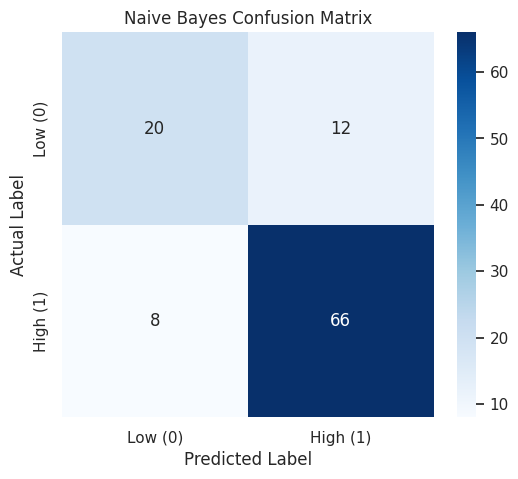

In [131]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Compute confusion matrix dynamically from test predictions
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rejected (0)', 'Approved (1)'],
            yticklabels=['Rejected (0)', 'Approved (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Naive Bayes Confusion Matrix')
plt.tight_layout()
plt.show()


In [132]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "SVM": SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    )
}

print("Number of models:", len(models))

Number of models: 8


In [133]:
results = []

for name, model in models.items():

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.858491,0.855422,0.959459,0.904459
1,Extra Trees,0.858491,0.847059,0.972973,0.905660
2,Random Forest,0.830189,0.850000,0.918919,0.883117
3,SVM,0.830189,0.825581,0.959459,0.887500
4,Hist Gradient Boosting,0.820755,0.857143,0.891892,0.874172
5,Decision Tree,0.801887,0.827160,0.905405,0.864516
6,Gradient Boosting,0.801887,0.835443,0.891892,0.862745
7,KNN,0.726415,0.747253,0.918919,0.824242


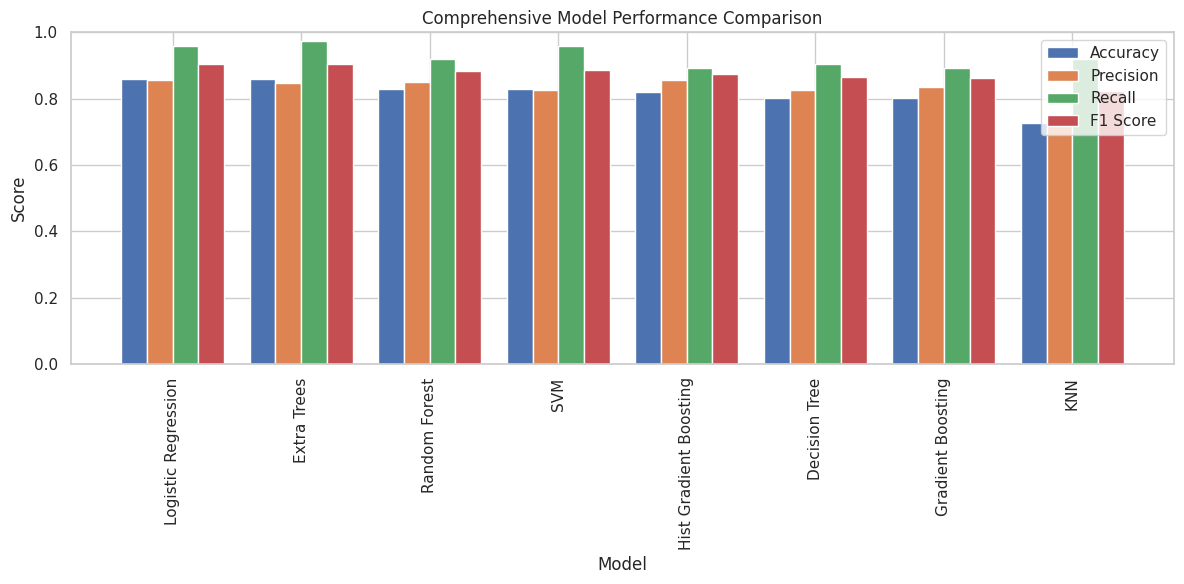

In [134]:

# Model positions
x = np.arange(len(results_df["Model"]))
width = 0.2

plt.figure(figsize=(12, 6))

# Plot metrics
plt.bar(x - 1.5 * width, results_df["Accuracy"], width, label="Accuracy")
plt.bar(x - 0.5 * width, results_df["Precision"], width, label="Precision")
plt.bar(x + 0.5 * width, results_df["Recall"], width, label="Recall")
plt.bar(x + 1.5 * width, results_df["F1 Score"], width, label="F1 Score")

# Title and labels
plt.title("Comprehensive Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")

# Model names
plt.xticks(x, results_df["Model"], rotation=90)

# Y-axis range
plt.ylim(0, 1)

# Display legend
plt.legend()

plt.tight_layout()
plt.show()

---

## K-Nearest Neighbors (KNN) Classifier - Detailed Evaluation

Number of models: 8
K-Nearest Neighbors Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.28      0.38        32
           1       0.75      0.92      0.82        74

    accuracy                           0.73       106
   macro avg       0.67      0.60      0.60       106
weighted avg       0.70      0.73      0.69       106



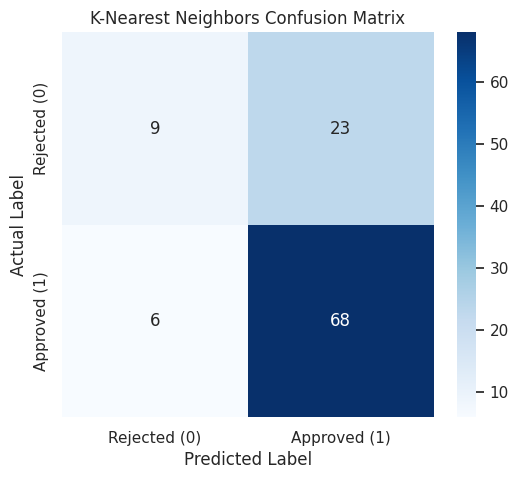

In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "SVM": SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    )
}

print("Number of models:", len(models))

# Retrieve the KNN model
knn_model = models["KNN"]

# Fit the KNN model explicitly
knn_model.fit(X_train, y_train)

# Make predictions using the KNN model
y_pred_knn = knn_model.predict(X_test)

# Display Classification Report for KNN
print("K-Nearest Neighbors Classification Report:")
print(classification_report(y_test, y_pred_knn))

# Display Confusion Matrix for KNN
cm_knn = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Rejected (0)', 'Approved (1)'],
    yticklabels=['Rejected (0)', 'Approved (1)'],
    cbar=True
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('K-Nearest Neighbors Confusion Matrix')
plt.show()

### KNN Decision Boundary Visualization

To visualize how the K-Nearest Neighbors (KNN) model classifies loan applications, we will plot the decision boundary using two key features: `Log_ApplicantIncome` and `Log_LoanAmount`. These log-transformed features represent the applicant's and loan's financial aspects, and their scaling helps create a clearer boundary.

A separate KNN model will be trained on these two features specifically for this visualization. The plot will show:

*   **Background Colors**: The regions classified by the KNN model as 'Loan Rejected' (Class 0) or 'Loan Approved' (Class 1).
*   **Data Points**: The actual test data points, colored according to their true `Loan_Status`.

This helps us understand the geometric separation created by the KNN algorithm.

In [ ]:
# Select two key features for 2D visualization
X_viz = X_train[['Log_ApplicantIncome', 'Log_LoanAmount']]
y_viz = y_train

X_test_viz = X_test[['Log_ApplicantIncome', 'Log_LoanAmount']]
y_test_viz = y_test

# Train a new KNN model specifically for the visualization (on 2 features)
knn_viz_model = KNeighborsClassifier(n_neighbors=knn_model.n_neighbors, weights=knn_model.weights)
knn_viz_model.fit(X_viz, y_viz)

# Create a meshgrid to plot the decision boundary
x_min, x_max = X_test_viz['Log_ApplicantIncome'].min() - 0.5, X_test_viz['Log_ApplicantIncome'].max() + 0.5
y_min, y_max = X_test_viz['Log_LoanAmount'].min() - 0.5, X_test_viz['Log_LoanAmount'].max() + 0.5
h = 0.02 # Step size in the mesh

xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# Predict class for each point in the meshgrid
Z = knn_viz_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary and actual test points
plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, alpha=0.8, cmap='viridis_r')

# Plot the test data points
sns.scatterplot(x=X_test_viz['Log_ApplicantIncome'],
                y=X_test_viz['Log_LoanAmount'],
                hue=y_test_viz, # Color by true class (0: Rejected, 1: Approved)
                palette={0: '#e05c5c', 1: '#5dbf85'}, # Red for Rejected, Green for Approved
                marker='o', s=100, edgecolor='k', alpha=0.8,
                legend='full')

plt.title('KNN Decision Boundary (Log_ApplicantIncome vs. Log_LoanAmount)')
plt.xlabel('Log_ApplicantIncome')
plt.ylabel('Log_LoanAmount')
plt.legend(title='Loan Status', labels=['Approved (1)', 'Rejected (0)']) # Custom legend labels
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()